Load the activity names and the train and test feature, label, and subject files.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("../data/UCI HAR Dataset")
activity_labels = pd.read_csv(DATA_DIR / "activity_labels.txt", sep=r"\s+", header=None)
activity_names = dict(zip(activity_labels[0], activity_labels[1]))
class_ids = sorted(activity_names)

X_train = pd.read_csv(DATA_DIR / "train/X_train.txt", sep=r"\s+", header=None)
y_train = pd.read_csv(DATA_DIR / "train/y_train.txt", sep=r"\s+", header=None)
subject_train = pd.read_csv(DATA_DIR / "train/subject_train.txt", sep=r"\s+", header=None)

X_test = pd.read_csv(DATA_DIR / "test/X_test.txt", sep=r"\s+", header=None)
y_test = pd.read_csv(DATA_DIR / "test/y_test.txt", sep=r"\s+", header=None)
subject_test = pd.read_csv(DATA_DIR / "test/subject_test.txt", sep=r"\s+", header=None)

Fit a most-frequent baseline and print its test accuracy.

In [2]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train[0])
baseline_accuracy = accuracy_score(y_test[0], baseline.predict(X_test))
print(f"Baseline test accuracy: {baseline_accuracy:.3f}")

Baseline test accuracy: 0.182


Fit a scaled neural network on the training features and report test performance by activity.

In [3]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(128, 64),
        early_stopping=True,
        max_iter=300,
        random_state=42,
    )),
])
model.fit(X_train, y_train[0])
y_pred = model.predict(X_test)
model_accuracy = accuracy_score(y_test[0], y_pred)
print(f"Model test accuracy: {model_accuracy:.3f}")
print(classification_report(
    y_test[0], y_pred,
    labels=class_ids,
    target_names=[activity_names[class_id] for class_id in class_ids],
))

Model test accuracy: 0.944
                    precision    recall  f1-score   support

           WALKING       0.95      0.99      0.97       496
  WALKING_UPSTAIRS       0.94      0.95      0.94       471
WALKING_DOWNSTAIRS       0.97      0.92      0.95       420
           SITTING       0.93      0.89      0.91       491
          STANDING       0.89      0.94      0.91       532
            LAYING       1.00      0.98      0.99       537

          accuracy                           0.94      2947
         macro avg       0.95      0.94      0.94      2947
      weighted avg       0.95      0.94      0.94      2947



Plot the test confusion matrix with activity names on both axes.

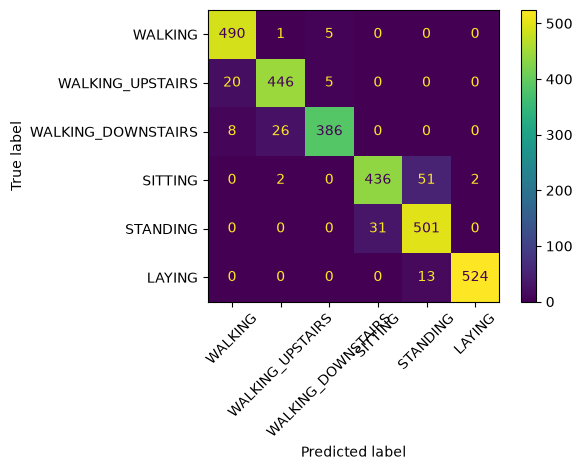

In [4]:
ConfusionMatrixDisplay.from_predictions(
    y_test[0], y_pred,
    labels=class_ids,
    display_labels=[activity_names[class_id] for class_id in class_ids],
    xticks_rotation=45,
)
plt.tight_layout()
plt.show()

Print the three most frequent true-to-predicted mistake pairs.

In [5]:
matrix = confusion_matrix(y_test[0], y_pred, labels=class_ids)
mistakes = sorted(
    (
        {"true_label": activity_names[true_id],
         "predicted_label": activity_names[pred_id],
         "count": int(matrix[i, j])}
        for i, true_id in enumerate(class_ids)
        for j, pred_id in enumerate(class_ids)
        if i != j and matrix[i, j] > 0
    ),
    key=lambda item: (-item["count"], item["true_label"], item["predicted_label"]),
)
top_confusions = mistakes[:3]
for item in top_confusions:
    print(f'{item["true_label"]} → {item["predicted_label"]}: {item["count"]}')

SITTING → STANDING: 51
STANDING → SITTING: 31
WALKING_DOWNSTAIRS → WALKING_UPSTAIRS: 26


Sample up to ten test windows per activity, prioritizing misclassified walking windows, and export predictions with raw acceleration.

In [6]:
rng = np.random.default_rng(42)
true_ids = y_test[0].to_numpy()
priority_names = {"WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS"}
selected = []
for class_id in class_ids:
    candidates = np.flatnonzero(true_ids == class_id)
    if activity_names[class_id] in priority_names:
        errors = candidates[y_pred[candidates] != class_id]
        priority = rng.choice(errors, size=min(10, len(errors)), replace=False).tolist()
    else:
        priority = []
    remaining = np.setdiff1d(candidates, priority, assume_unique=True)
    extra = rng.choice(remaining, size=min(10 - len(priority), len(remaining)), replace=False).tolist()
    selected.extend(priority + extra)

signal_dir = DATA_DIR / "test/Inertial Signals"
signals = {
    axis: pd.read_csv(signal_dir / f"total_acc_{axis}_test.txt", sep=r"\s+", header=None)
    for axis in ("x", "y", "z")
}
probabilities = model.predict_proba(X_test.iloc[selected])
probability_classes = model.classes_

predictions = []
for index, row_probabilities in zip(selected, probabilities):
    true_name = activity_names[int(true_ids[index])]
    predicted_name = activity_names[int(y_pred[index])]
    predictions.append({
        "id": int(index),
        "subject": int(subject_test.iloc[index, 0]),
        "true_label": true_name,
        "predicted_label": predicted_name,
        "correct": bool(true_ids[index] == y_pred[index]),
        "class_probabilities": {
            activity_names[int(class_id)]: round(float(probability), 3)
            for class_id, probability in zip(probability_classes, row_probabilities)
        },
        "total_acc": {
            axis: np.round(signal.iloc[index].to_numpy(), 3).tolist()
            for axis, signal in signals.items()
        },
    })

output_dir = Path("../docs/data")
output_dir.mkdir(parents=True, exist_ok=True)
(output_dir / "predictions.json").write_text(
    json.dumps(predictions, indent=2), encoding="utf-8"
)
print(f"Exported {len(predictions)} windows to {output_dir / 'predictions.json'}")

Exported 60 windows to ..\site\data\predictions.json


Export baseline and model accuracy, recall for each activity, and the top confusion pairs.

In [7]:
report = classification_report(
    y_test[0], y_pred,
    labels=class_ids,
    target_names=[activity_names[class_id] for class_id in class_ids],
    output_dict=True,
)
metrics = {
    "baseline_accuracy": float(baseline_accuracy),
    "model_accuracy": float(model_accuracy),
    "per_class_recall": {
        activity_names[class_id]: float(report[activity_names[class_id]]["recall"])
        for class_id in class_ids
    },
    "top_confusions": top_confusions,
}
(output_dir / "metrics.json").write_text(
    json.dumps(metrics, indent=2), encoding="utf-8"
)
print(f"Exported metrics to {output_dir / 'metrics.json'}")

Exported metrics to ..\site\data\metrics.json


## Findings

**Results (9 unseen test subjects):** Most-frequent baseline (always LAYING) = 18.2% accuracy. Neural network (StandardScaler + MLP 128→64, early stopping) = 94.4%.

**Most common mistakes:** sitting → standing (51), standing → sitting (31), walking downstairs → walking upstairs (26), walking upstairs → walking (20).

**Highlighted mistake — downstairs predicted as upstairs (26 windows):** Both have the same ~0.5 s step rhythm, and a waist-worn phone sees similar periodic acceleration in either direction. What might help: a barometer to sense altitude change, longer windows (2.56 s ≈ 4 steps), or training data from more than 21 people.

**Chatbot testing (WebLLM, guide-grounded):**
- Q1 (data source) answered correctly after adding an FAQ section to the guide.
- Q2/Q3 initially came back garbled or repeated; the first Q3 answer implied untested performance (unsupported claim). Fixed by sending each question without chat history and adding an explicit "unknown — never tested on other datasets" FAQ entry.
- On our integrated-GPU Windows laptop, WebLLM repeatedly hit GPU device-lost errors (Chrome and Edge; Llama 1B, Qwen 0.5B, SmolLM2 360M; f16 and f32). The exhibit stays usable via an opt-in button, progress display, and a device-lost fallback message. Live chat needs a device with a stronger GPU.